# Project data exploration - looking at relplot and scatter plots
Using a dataset that your group is consider using for the term project, let's do some data exploring of the different features in your dataset and their relationships

Group name: Group 2
Created by NAMES (SJSU IDs)  
Last updated: DATE  
Briefly describe your dataset

Import your data. If you want to mount your Google drive you can use `from google.colab import drive` and `drive.mount('/content/drive')`

In [2]:
import pandas as pd
from pathlib import Path

In [3]:
ROOT_DIR = Path.cwd()
data_path = (ROOT_DIR.parent/"data"/"ObesityDataSet_raw_and_data_sinthetic.csv").resolve()
df = pd.read_csv(data_path)

In [4]:
df.head()
# df.tail()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [5]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


## Q1: Data background
Provide a brief summary of the data including source, size of data, topic, and what the motivation behind exploring this dataset.

This dataset is called "Estimation of Obesity Levels Based On Eating Habits and Physical Condition" from the UCI Machine Learning Repository. The size of this dataset is 56.3 KB with 16 features and 2111 instances. This data is includes estimation of obesity levels in individuals from Mexico, Peru, Colombia depending on their eating habits and physical condition. Obesity is a problem that affects many people. By exploring this dataset we can find what contributes to obesity and help people make inform decisions about their eating habits and physical lifestyle to reduce risk of obesity.


### Q2: Show the number of missing data in each column of the dataframe
If you have missing data, how much? which column(s)? Do you think it will impact your output?

In [6]:
# Checking to see if string columsn have odd values that could be categorized as NA
# for col in df.select_dtypes(include=["object", "category"]).columns:
#     print(df[col].unique())
#     print("_______________")

df.isna().sum() 
# There is no missing data

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

### Q3: Show the data type for each column of the dataframe
Is the data type as expected? Is it clear what the content/value of each column is?

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

Some of the data types are to be expected except for:
    * Age was expected to be a integer not a float,
    * Gender, CAEC, CALC, MTRANS, NObeyesdad are expected to be categorical,
    * family_history_with_overweight, FAVC, FCVC, SMOKE SCC are expected to be categorical or mapped to 0 or 1.

Around half of columns are not very clear regarding its content because of the acronyms. Unless you already know what the each stands for or read the description for dataset from the UCI ML repository.

### Q4: Your own question using `relplot()`
Come up with your own question to do the initital exploration of your data that utilizes the `relplot()` package to understand relationships between two variables.

Text(56.03897222222221, 0.5, 'Weight (kg))')

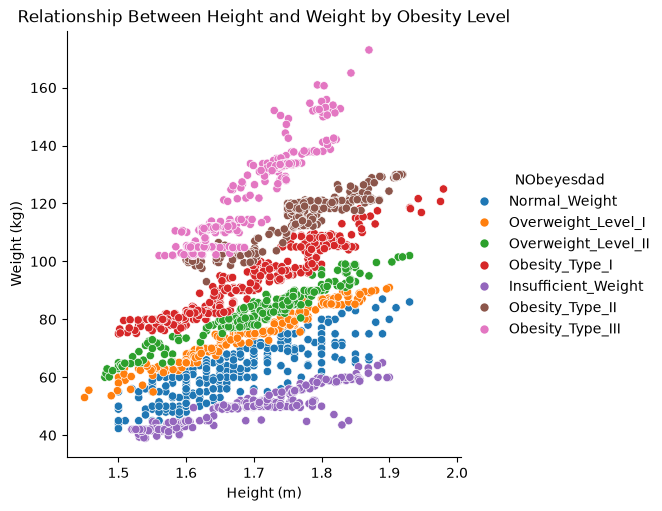

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.relplot(
    data=df,
    x="Height",
    y="Weight",
    hue="NObeyesdad",
)

plt.title("Relationship Between Height and Weight by Obesity Level")
plt.xlabel("Height (m)")
plt.ylabel("Weight (kg))")

### Q5: Your own question using `catplot()`
Come up with your own question to do the initital exploration of your data that utilizes the `catplot()` package to understand categorical variables in your dataset.

Question: How does having a family history of being overweight relate to a person’s obesity level?

Text(49.53710648148149, 0.5, 'Number of People')

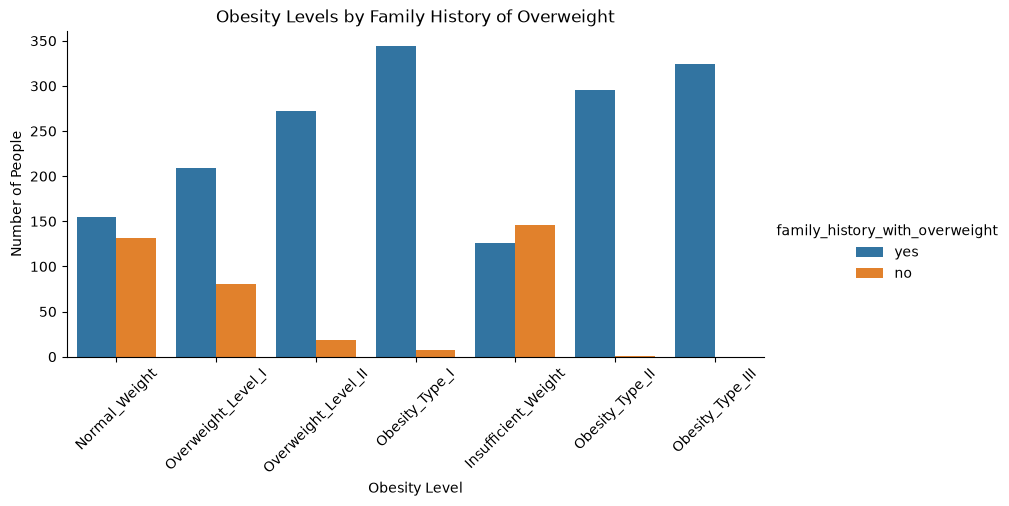

In [15]:
sns.catplot(
    data=df,
    x="NObeyesdad",
    hue="family_history_with_overweight",
    kind="count",
    height=4,
    aspect=2
)

plt.xticks(rotation=45)
plt.title("Obesity Levels by Family History of Overweight")
plt.xlabel("Obesity Level")
plt.ylabel("Number of People")

### Q6: Create a plot with small multiples plots
Select two features from your dataset and show the relationship between the features with an additional feature as the single category. Organize the multiple plots to have 3 plots per row. Set the `height` of the plot to 5 and the size the of data point to 20. Include a meaningful title in the plot.

In [10]:
# Your code here . . .